In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
data = {
    "email": [
        "Win a free prize now",
        "Claim your free cash reward",
        "Congratulations you won a lottery",
        "Free entry in a lucky draw",
        "Get money fast click now",
        "Exclusive offer claim your prize",
        "You have won free tickets",
        "Urgent claim your cash now",
        "Meeting scheduled for tomorrow",
        "Please send me the project report",
        "Can we meet for lunch today",
        "The assignment deadline is Friday",
        "Please review the attached document",
        "Your appointment is confirmed",
        "Let us discuss the project",
        "The lecture starts at ten",
        "Please call me when you are free",
        "The meeting has been postponed",
        "Your report looks good",
        "I will send the notes tomorrow"
    ],
    "label": [
        "Spam", "Spam", "Spam", "Spam", "Spam",
        "Spam", "Spam", "Spam",
        "Not Spam", "Not Spam", "Not Spam", "Not Spam",
        "Not Spam", "Not Spam", "Not Spam", "Not Spam",
        "Not Spam", "Not Spam", "Not Spam", "Not Spam"
    ]
}

df = pd.DataFrame(data)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

                               email label
0               Win a free prize now  Spam
1        Claim your free cash reward  Spam
2  Congratulations you won a lottery  Spam
3         Free entry in a lucky draw  Spam
4           Get money fast click now  Spam

Dataset shape: (20, 2)

Class distribution:
label
Not Spam    12
Spam         8
Name: count, dtype: int64


In [3]:
X = df["email"]
y = df["label"]

print("Input features:")
print(X.head())

print("\nTarget labels:")
print(y.head())

Input features:
0                 Win a free prize now
1          Claim your free cash reward
2    Congratulations you won a lottery
3           Free entry in a lucky draw
4             Get money fast click now
Name: email, dtype: str

Target labels:
0    Spam
1    Spam
2    Spam
3    Spam
4    Spam
Name: label, dtype: str


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15
Testing samples: 5


In [5]:
vectorizer = CountVectorizer()

X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_vectorized.shape)
print("Testing feature matrix:", X_test_vectorized.shape)

Training feature matrix: (15, 53)
Testing feature matrix: (5, 53)


In [6]:
model = MultinomialNB(alpha=1.0)

model.fit(X_train_vectorized, y_train)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


In [7]:
y_pred = model.predict(X_test_vectorized)

results = pd.DataFrame({
    "Email": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.to_string(index=False))

                            Email   Actual Predicted
        The lecture starts at ten Not Spam  Not Spam
The assignment deadline is Friday Not Spam  Not Spam
       Urgent claim your cash now     Spam      Spam
Congratulations you won a lottery     Spam      Spam
       Let us discuss the project Not Spam  Not Spam


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: {:.2f}%".format(accuracy * 100))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

    Not Spam       1.00      1.00      1.00         3
        Spam       1.00      1.00      1.00         2

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



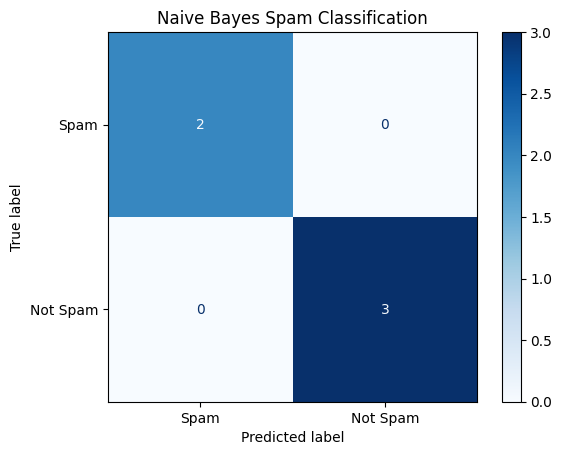

In [9]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Spam", "Not Spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Spam", "Not Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes Spam Classification")
plt.show()

In [10]:
new_emails = [
    "Congratulations win free cash now",
    "Please send the project report tomorrow"
]

new_emails_vectorized = vectorizer.transform(new_emails)

predictions = model.predict(new_emails_vectorized)
probabilities = model.predict_proba(new_emails_vectorized)

for email, prediction, probability in zip(
    new_emails, predictions, probabilities
):
    print("Email:", email)
    print("Prediction:", prediction)

    for label, prob in zip(model.classes_, probability):
        print(f"{label} Probability: {prob:.2%}")

    print("-" * 40)

Email: Congratulations win free cash now
Prediction: Spam
Not Spam Probability: 2.30%
Spam Probability: 97.70%
----------------------------------------
Email: Please send the project report tomorrow
Prediction: Not Spam
Not Spam Probability: 99.81%
Spam Probability: 0.19%
----------------------------------------


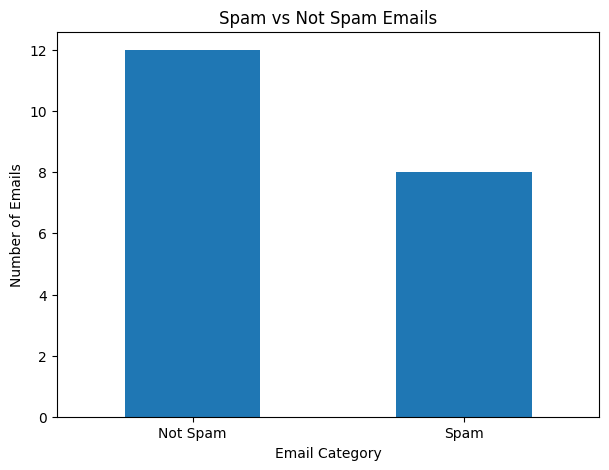

In [11]:
df["label"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Spam vs Not Spam Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")
plt.xticks(rotation=0)
plt.show()